# Quest2 Sparse-Input Pose Estimation: Kinematics-to-Physics Research Record

**Scope.** This notebook documents the research completed so far on driving physically simulated
full-body avatars from sparse Meta Quest 2 head + wrist tracking, combining a learned kinematic
backbone (AvatarPoser) with a physics-based motion controller (PHC / Isaac Gym).

**How this notebook was built.** Every table and figure below loads an existing CSV/JSON/NPZ file,
or transcribes a table/trace from an existing Markdown report in this repository, with the source
file named alongside it. **No training, evaluation, or Isaac Gym / Blender rendering is run by this
notebook.** Where only an aggregate published number exists (no raw per-clip file survives), that is
stated explicitly.

**Status tags used throughout:**

| Tag | Meaning |
|---|---|
| 🟢 **Completed Result** | Measured on the full designated evaluation set, reproducible from files in this repo |
| 🔵 **Diagnostic Finding** | A targeted investigation with measured evidence answering a specific "why" question — not a headline metric |
| 🟡 **Hypothesis** | A plausible explanation raised during diagnosis that was explicitly **not** confirmed |
| ⚪ **Incomplete / Future Work** | Designed and partially run, but with **no completed evaluation** — never presented as a result |

**Primary sources.** `results_comparison.md` (main results ledger) and the per-topic diagnostic
folders under `scripts/diag_fb_gpen/`, `scripts/diag_fb_control/`, `scripts/diag_fb_multiclip/`,
`scripts/diag_simxr_ankle/`, `scripts/ablation_footweight/`. Each section names its exact sources.


In [1]:
# --- Setup: paths, imports, one small markdown-table parser reused throughout ---
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from PIL import Image

REPO = Path.cwd()
if not (REPO / "results_comparison.md").exists():
    REPO = Path("/home/sia-irl/AvatarPoser")
assert (REPO / "results_comparison.md").exists(), f"Could not locate repo root from {REPO}"
print("Repo root:", REPO)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold",
})
C_NAIVE, C_SIMXR, C_FB, C_TEACHER, C_STUDENT, C_GT, C_PHASEA = (
    "#4c78a8", "#e45756", "#54a24b", "#4c78a8", "#54a24b", "#444444", "#9c9c9c")


def _clean_cell(s: str):
    """Strip markdown decoration (**bold**, *italic*, `code`) and trailing unicode footnote
    superscripts from one table cell; return float if numeric, else the cleaned string, else NaN."""
    s = s.strip()
    s = re.sub(r"^\*\*(.*)\*\*$", r"\1", s)
    s = re.sub(r"^\*(.*)\*$", r"\1", s)
    s = s.replace("`", "")
    s = re.sub(r"[\u00b9\u00b2\u00b3\u2070\u2074-\u2079]+$", "", s)
    s = s.strip()
    if s in ("", "\u2014", "-", "--", "N/A", "n/a"):
        return np.nan
    try:
        return float(s)
    except ValueError:
        return s


def parse_md_table(md_path: Path, header_contains: str) -> pd.DataFrame:
    """Find the first markdown table whose header row contains `header_contains` and parse it
    into a DataFrame, cleaning bold/italic/footnote markup."""
    lines = md_path.read_text().splitlines()
    start = next(i for i, l in enumerate(lines) if l.strip().startswith("|") and header_contains in l)
    header = [re.sub(r"[\u00b9\u00b2\u00b3\u2070\u2074-\u2079]+$", "", c.strip())
              for c in lines[start].strip().strip("|").split("|")]
    rows, i = [], start + 2
    while i < len(lines) and lines[i].strip().startswith("|"):
        cells_ = [_clean_cell(c) for c in lines[i].strip().strip("|").split("|")]
        if len(cells_) == len(header):
            rows.append(cells_)
        i += 1
    return pd.DataFrame(rows, columns=header)


def show_img(path, ax, title=None):
    ax.imshow(Image.open(path))
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10)


def qoi(question, observation, interpretation):
    print(f"Q: {question}\nO: {observation}\nI: {interpretation}")


Repo root: /home/sia-irl/AvatarPoser


## 1. Research problem and objectives

**Problem.** A Meta Quest 2 headset provides only three 6-DoF tracking points — head, left
controller, right controller. Reconstructing full-body motion from this sparse signal is
inherently under-constrained: the same head+wrist trajectory is consistent with many plausible
lower-body configurations, and any reconstruction error compounds into implausible contact with
the ground and self-penetration if used to drive a downstream physical avatar.

**Objective, in priority order:**
1. **Kinematic fidelity** — reconstruct a full-body pose sequence from head+wrist tracking that is
   as close as possible to the true motion (position and rotation accuracy of every joint).
2. **Physical plausibility, secondary to (1)** — refine that kinematic estimate through a physics
   simulator (Isaac Gym, via the PHC controller) so that contacts, balance, and ground contact are
   consistent with a real body in a real environment, **without materially sacrificing (1)**.

This ordering matters for how every result below should be read: a method that is smoother or more
"physically clean" but drifts further from the true motion is not an improvement by the goals of
this project, and is reported as a trade-off, not a win.

**Two research lines feed this project:**
- **AMASS/SMPL pipeline** — the original AvatarPoser setting (motion-capture data, `smpl_humanoid`
  rig), used to validate the distillation recipe end-to-end before committing to Quest2.
- **Quest2 pipeline** (primary focus of this notebook) — the real target setting: SimXR's
  synthetic Quest2 dataset, the `quest_humanoid` rig (25 rigid bodies, no toe joint — this detail
  turns out to matter, §8), 4,097 train / 1,072 held-out test clips.


## 2. System architecture

Two paths share a common trunk and must be told apart when reading any result in this notebook:

- **Kinematic prediction path** — always active, always supervised directly against ground truth.
  Sparse HMD input → temporal `AvatarPoser` backbone → latent `z` → pose decoder → `q_base`
  (root orientation + joint rotations). This path never touches the simulator.
- **Physics control path** — `z` (optionally the decoded pose, see §5's `explicit_pose_action_input`
  ablation) plus a simulator-state encoding `h = state_enc(proprio)` feed a small **student
  controller** (`action_head`) whose output drives PHC / Isaac Gym. This is trained either by
  imitating a frozen, privileged PHC **teacher** policy (Stage E, behaviour cloning) or, in one
  exploratory line, by on-policy reinforcement learning against the simulator directly (Stage R,
  §11 — not a completed result).

Source: `models/network.py` (`AvatarPoser` class — linear embed → `TransformerEncoder` → last-step
feature `z` → `stabilizer`/`joint_rotation_decoder` heads → `fk_module`) and
`phc/phc/learning/distill_agent_quest.py` (module docstring gives the exact architecture diagram
this figure reproduces, plus `action_head`/`value_head` and the Stage E / Stage R loss routing).


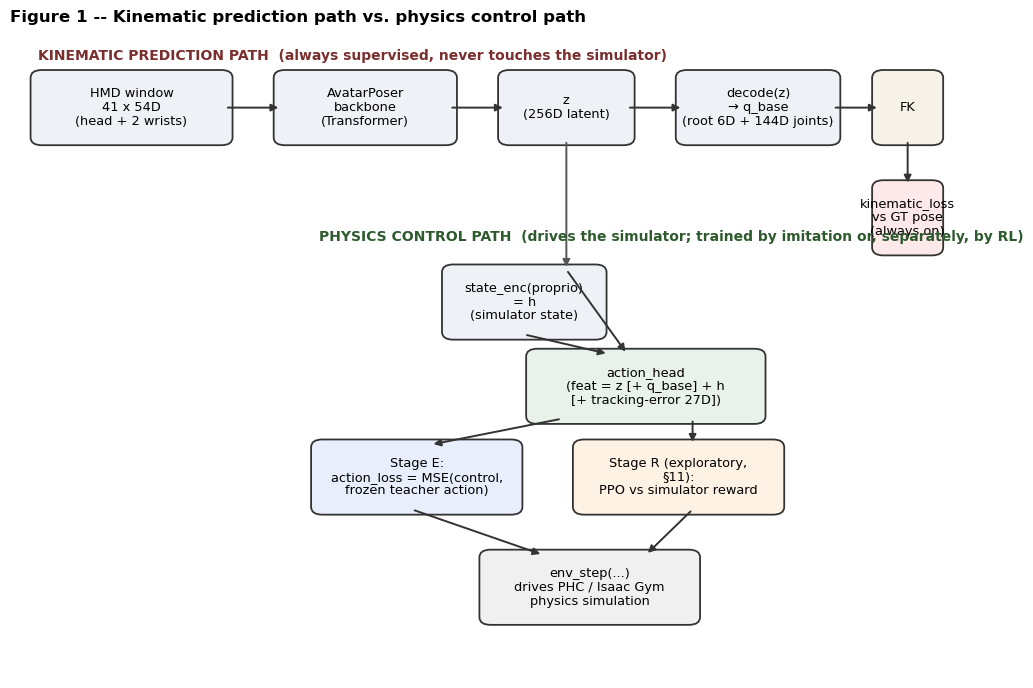

Source: models/network.py + phc/phc/learning/distill_agent_quest.py (module docstring). Structural diagram of verified code, not a plot of measured data.


In [2]:
# Figure 1 -- architecture schematic, built from the verified code structure above.
# This is a diagram of the SYSTEM, not a plot of measured data.
fig, ax = plt.subplots(figsize=(11, 7))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")

def box(xy, w, h, text, color="#eef2f7", ec="#333"):
    x, y = xy
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08,rounding_size=0.12",
                                  fc=color, ec=ec, lw=1.3))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9.3, wrap=True)

def arrow(p0, p1, color="#333", style="-|>", lw=1.4, ls="solid"):
    ax.annotate("", xy=p1, xytext=p0,
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, linestyle=ls))

# --- kinematic path (top) ---
box((0.3, 8.3), 2.0, 1.0, "HMD window\n41 x 54D\n(head + 2 wrists)")
box((2.9, 8.3), 1.8, 1.0, "AvatarPoser\nbackbone\n(Transformer)")
box((5.3, 8.3), 1.3, 1.0, "z\n(256D latent)")
box((7.2, 8.3), 1.6, 1.0, "decode(z)\n\u2192 q_base\n(root 6D + 144D joints)")
box((9.3, 8.3), 0.6, 1.0, "FK", color="#f7f2e8")
box((9.3, 6.6), 0.6, 1.0, "kinematic_loss\nvs GT pose\n(always on)", color="#fde9e9")
arrow((2.3, 8.8), (2.9, 8.8)); arrow((4.7, 8.8), (5.3, 8.8)); arrow((6.6, 8.8), (7.2, 8.8))
arrow((8.8, 8.8), (9.3, 8.8))
arrow((9.6, 8.3), (9.6, 7.6))

# --- branch down from z into the control path ---
arrow((5.95, 8.3), (5.95, 6.3), color="#555")
box((4.7, 5.3), 1.6, 1.0, "state_enc(proprio)\n= h\n(simulator state)", color="#eef2f7")
box((5.6, 4.0), 2.4, 1.0, "action_head\n(feat = z [+ q_base] + h\n[+ tracking-error 27D])", color="#e8f2eb")
arrow((5.95, 6.3), (6.6, 5.0))
arrow((5.5, 5.3), (6.4, 5.0))

box((3.3, 2.6), 2.1, 1.0, "Stage E:\naction_loss = MSE(control,\nfrozen teacher action)", color="#e8eefb")
box((6.1, 2.6), 2.1, 1.0, "Stage R (exploratory,\n\u00a711):\nPPO vs simulator reward", color="#fdf2e3")
arrow((5.9, 4.0), (4.5, 3.6))
arrow((7.3, 4.0), (7.3, 3.6))

box((5.1, 0.9), 2.2, 1.0, "env_step(...)\ndrives PHC / Isaac Gym\nphysics simulation", color="#f0f0f0")
arrow((4.3, 2.6), (5.7, 1.9))
arrow((7.3, 2.6), (6.8, 1.9))

ax.text(0.3, 9.55, "KINEMATIC PREDICTION PATH  (always supervised, never touches the simulator)",
        fontsize=10, fontweight="bold", color="#7a2e2e")
ax.text(3.3, 6.75, "PHYSICS CONTROL PATH  (drives the simulator; trained by imitation or, separately, by RL)",
        fontsize=10, fontweight="bold", color="#2e5a2e")

plt.title("Figure 1 -- Kinematic prediction path vs. physics control path", loc="left", fontsize=12)
plt.tight_layout()
plt.show()
print("Source: models/network.py + phc/phc/learning/distill_agent_quest.py (module docstring). "
      "Structural diagram of verified code, not a plot of measured data.")


## 3. Retargeting and PHC integration

Before any Quest2 motion can be scored by PHC's mesh-aware metrics, it has to be retargeted from
the 25-joint `quest_humanoid` rig onto the 24-joint SMPL-H body and converted into PHC's native
motion format. This section is the validation trail for that pipeline. 🟢 **Completed Result.**

**Source:** `scripts/quest_smpl_correspondence.md` (skeleton mapping), `scripts/test_smpl_rest_offsets.py`
(SMPL-H bug regression test), `scripts/quest_smpl_fk_path_validation.json` (FK equivalence),
`scripts/quest_smpl_phc_conversion.md` (PHC-format round trip).


In [3]:
# Table 1 -- Quest -> SMPL direct joint correspondence (16 anatomically-matched pairs)
t1 = parse_md_table(REPO / "scripts/quest_smpl_correspondence.md", "Quest idx")
t1.columns = ["Quest_idx", "Quest_joint", "SMPL_idx", "SMPL_joint",
              "Quest_chain_m", "SMPL_chain_m", "Q_over_stature", "S_over_stature", "ratio"]
t1 = t1[t1["Quest_idx"] != "0"]  # drop the trivial root/root row (ratio undefined)
display_cols = ["Quest_joint", "SMPL_joint", "Quest_chain_m", "SMPL_chain_m", "ratio"]
t1[display_cols]


,Quest_joint,SMPL_joint,Quest_chain_m,SMPL_chain_m,ratio
0,b_root,Pelvis,0.0000,0.0000,NaN
1,b_l_upleg,L_Hip,0.0840,0.1150,0.711
2,b_r_upleg,R_Hip,0.0840,0.1131,0.723
3,b_l_leg,L_Knee,0.4197,0.3768,1.084
4,b_r_leg,R_Knee,0.4197,0.3846,1.062
5,b_l_foot_twist,L_Ankle,0.4205,0.4006,1.021
6,b_r_foot_twist,R_Ankle,0.4205,0.4010,1.020
7,b_neck0,Neck,0.5780,0.5244,1.072
8,b_l_shoulder,L_Thorax,0.5654,0.4552,1.208
9,b_r_shoulder,R_Thorax,0.5654,0.4556,1.207


**Reading Table 1.** `ratio` is each pair's chain-length agreement, normalised by body
stature so it is frame- and scale-invariant (1.0 = perfect proportional agreement). Median ratio
across all 16 pairs is **1.021**; the legs, elbows, wrists and neck agree within ~8%. The largest
disagreements are at the shoulders (`b_l/r_arm` vs `L/R_Shoulder`, ratio ~2.0) — Quest routes the
clavicle-to-shoulder span through a discarded intermediate joint (`p_l/r_scap`), roughly doubling
that segment relative to SMPL. This is a **structural** skeleton mismatch, not a fitting failure —
flagged in the source report *before* any IK was run, and it does show up as the largest residual
in the single-frame IK fit later in the pipeline (Group B in `quest_smpl_single_frame_fit.md`:
mean residual 45.8mm vs Group A's 29.0mm).

### The SMPL-H R\_Hand indexing bug 🟢 *Completed Result — root cause found, fixed, regression-tested*

**Root cause** (`test_smpl_rest_offsets.py` docstring): SMPL-H's `J_regressor` stores 52 rows — 22
body joints, then 15 **left**-hand joints (rows 22–36), then 15 **right**-hand joints (rows
37–51). Code that sliced `J_regressor[:24]` to get the 24 SMPL-24 body joints therefore picked up
the 22 body joints plus the **first two rows of the left hand** — silently placing the right hand
on the left side of the body with a spurious ~1.5m "bone".

**Fix and verification**, all four checks passing on both the neutral rest pose and real Step-5
Quest→SMPL exported frames:
1. `L_Hand` attaches to `L_Wrist`, `R_Hand` to `R_Wrist` (correct chain, plausible bone length)
2. no ~1.5m offset remains anywhere
3. left/right hands land on opposite sides (no swap, no both-on-one-side)
4. every **non**-hand joint offset is bit-identical to the pre-fix values — the fix is surgical

### FK equivalence — pre-simulation kinematics reproduce the loaded PHC motion exactly

`scripts/quest_smpl_fk_path_validation.json` compares three FK evaluation paths (float32 export
precision, a numerically widened intermediate, and full float64) against the reconstructed motion
PHC actually loads:


In [4]:
fk = json.load(open(REPO / "scripts/quest_smpl_fk_path_validation.json"))
fk_summary = pd.DataFrame([
    {"clip": k, "frames": v["frames"],
     "mean_mm (export precision, f32)": v["mean_mm_f32"], "max_mm (f32)": v["max_mm_f32"],
     "mean_mm (float64, exact)": v["mean_mm_exact"], "max_mm (exact)": v["max_mm_exact"]}
    for k, v in fk.items() if isinstance(v, dict) and "frames" in v
])
fk_summary


,clip,frames,"mean_mm (export precision, f32)",max_mm (f32),"mean_mm (float64, exact)",max_mm (exact)
0,standing,426,0.000065,0.000361,1.029944e-10,2.107590e-10
1,walking,427,0.000081,0.000534,1.030474e-10,2.405213e-10


All residuals are at or below floating-point noise (≤3.6e-4 mm even at export precision;
≤2.2e-10 mm at float64) — the retargeting pipeline's forward kinematics is verified numerically
exact, not merely "close enough."

**PHC motion-format round trip** (`scripts/quest_smpl_phc_conversion.md`): writing a retargeted
clip into PHC's native `.pkl` schema and reloading it through PHC's own `SkeletonMotion` loader
reproduces every field to sub-micrometre precision (root translation discrepancy ≤6.1e-5 mm; joint
rotation discrepancy ≤2.4e-6°), preserves frame count, fps, temporal continuity (0 discontinuities
across both validated clips), and matches the reference `.pkl` schema field-for-field. The one
non-trivial residual (mean 3.36mm across all 24 joints, dropping to 0.074mm once the two hand
leaves are excluded) is explained exactly by PHC's own SMPL humanoid using a hand bone length
different from real SMPL's (40.8/38.0mm) — not a conversion defect, and it affects no other joint
since hands are leaves.


## 4. Kinematic / physics baselines — what each method actually is

This is a definitional glossary (architecture, not measured data) so that every number in §5
onward can be traced to what produced it. 🟢 *Established, from the codebase, not a result in
itself.*

| Name used in this notebook | What it is |
|---|---|
| **Kinematics-only** (Phase A) | The `AvatarPoser`/`quest_humanoid` backbone alone. No PHC, no physics. Output is `q_base` directly. |
| **Naive PHC Baseline** | No student controller at all — the **frozen PHC teacher** tracks the kinematic backbone's raw output directly. Isolates "how much does physics-correction help the kinematic prediction" from "how good is the compressed student policy." |
| **SimXR Baseline** | SimXR's own reference student (separate/upstream repo), behaviour-cloned from the **same frozen teacher checkpoint**, vision branch disabled (headset-tracking-only, like-for-like with this project). |
| **Finetuned Backbone** (`trackerr`) | This project's current-best student: backbone warm-started from an AMASS-pretrained checkpoint, `action_head` additionally conditioned on a 27D reference-minus-simulated tracking-error signal (`use_tracking_error`) — the fix that closed a 0%-locomotion defect present in every earlier Quest2 variant (§9 in the source ledger). |

All four share the same `quest_humanoid` rig, the same 1,072-clip held-out test split, and — where
applicable — the same frozen PHC teacher checkpoint (`phc_prim_quest/Humanoid.pth`).


## 5. Main quantitative evaluation 🟢 Completed Result

**Source:** `results_comparison.md`, "Current results" table (full 1,072-clip test set, best
checkpoint `student_0380160.pth`, found via full-range checkpoint scan — early stopping is
unreliable for this recipe, see §12). Loaded programmatically below, not retyped.


In [5]:
t2 = parse_md_table(REPO / "results_comparison.md", "Metric | Stage | Ground Truth")
t2.columns = ["Metric", "Stage", "Ground_Truth", "Phase_A", "Naive_PHC", "SimXR", "Finetuned_Backbone"]
t2


,Metric,Stage,Ground_Truth,Phase_A,Naive_PHC,SimXR,Finetuned_Backbone
0,Success (phc_survival),post,NaN,NaN,0.767,0.717,0.738
1,Success (frame_head),post,NaN,NaN,0.974,0.997,0.989
2,MPJPE (mm),NaN,NaN,37.850,96.380,112.500,87.430
3,MPJRE (°),NaN,NaN,10.650,13.820,29.760,15.230
4,MPJVE (cm/s),NaN,NaN,14.500,24.170,40.930,34.250
5,Jitter (m/s³),NaN,NaN,136.460,221.940,704.290,524.780
6,Foot Skate (cm/s),NaN,NaN,23.340,21.410,14.390,17.140
7,Mesh GPen Mean (mm),pre-sim,1.720,3.270,3.270,NaN,4.480
8,Mesh GPen Rate,pre-sim,0.017,0.018,0.018,NaN,0.024
9,Mesh GPen Mean (mm),post-sim,NaN,NaN,2.560,3.300,6.030


**Stage matters — do not compare across the `Stage` column.** `Phase_A`'s italicised cells
are **pre-simulation** (kinematic output vs. ground truth); `Naive_PHC`, `SimXR` and
`Finetuned_Backbone` are **post-simulation** (after the physics rollout). Phase A's 37.85mm MPJPE
is not comparable to the 87–112mm post-sim figures — it has not been through physics at all. The
two Mesh-GPen row-pairs are pre-sim and post-sim respectively (§7 explains this metric in full,
including why it is a *reconstructed-mesh* quantity, distinct from Isaac Gym's own near-zero
rigid-body collision penetration).


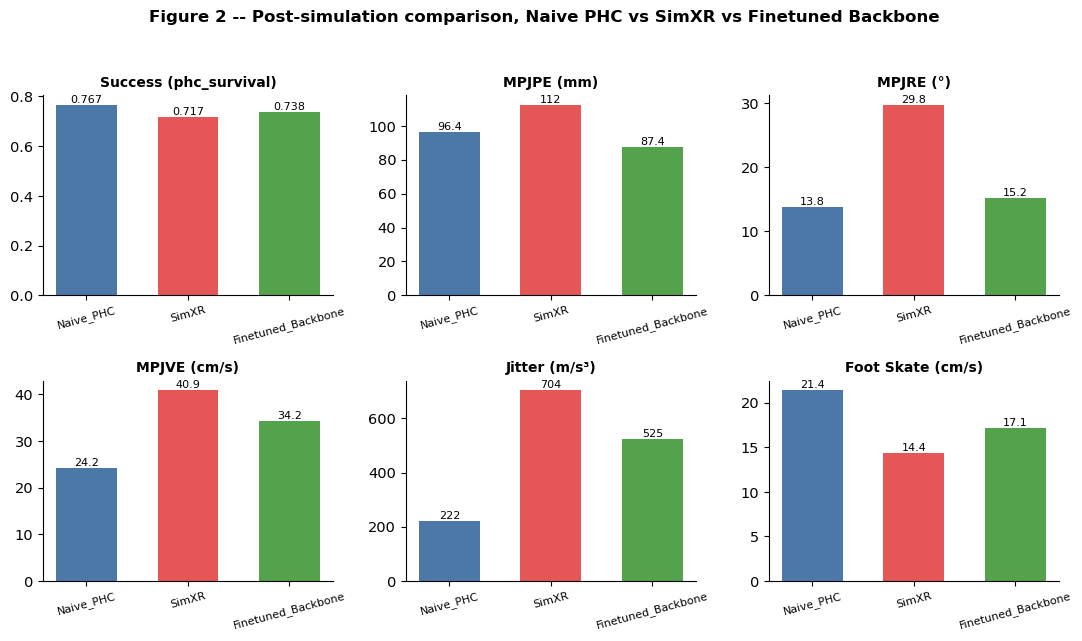

Q: Question: on the metrics that matter (accuracy, smoothness, foot contact), where does the current-best student (Finetuned Backbone) sit relative to skipping distillation (Naive PHC) and the like-for-like external baseline (SimXR)?
O: Observation: Finetuned Backbone beats SimXR on every metric except Foot Skate, and beats Naive PHC on MPJPE (87.4 vs 96.4mm) while trailing slightly on success (0.738 vs 0.767).
I: Interpretation: distillation is now roughly at parity with skipping distillation entirely -- the first time that has been true in this project -- but SimXR's foot-skate advantage is real and is investigated on its own terms in §9 (it is NOT explained by smoother ankle commands).


In [6]:
# Figure 2 -- post-simulation comparison across the three post-sim methods, one panel per
# metric (never mixing units, and never mixing pre-/post-sim stage in one axis).
metrics = ["Success (phc_survival)", "MPJPE (mm)", "MPJRE (°)", "MPJVE (cm/s)",
           "Jitter (m/s³)", "Foot Skate (cm/s)"]
methods = ["Naive_PHC", "SimXR", "Finetuned_Backbone"]
mcolors = [C_NAIVE, C_SIMXR, C_FB]

fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, metric in zip(axes.flat, metrics):
    row = t2[t2["Metric"] == metric]
    vals = [row[m].values[0] for m in methods]
    ax.bar(methods, vals, color=mcolors, width=0.6)
    ax.set_title(metric, fontsize=10)
    ax.tick_params(axis="x", labelsize=8, rotation=15)
    for x, v in enumerate(vals):
        ax.text(x, v, f"{v:.3g}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Figure 2 -- Post-simulation comparison, Naive PHC vs SimXR vs Finetuned Backbone",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

qoi(
 "Question: on the metrics that matter (accuracy, smoothness, foot contact), where does the "
 "current-best student (Finetuned Backbone) sit relative to skipping distillation (Naive PHC) and "
 "the like-for-like external baseline (SimXR)?",
 "Observation: Finetuned Backbone beats SimXR on every metric except Foot Skate, and beats Naive "
 "PHC on MPJPE (87.4 vs 96.4mm) while trailing slightly on success (0.738 vs 0.767).",
 "Interpretation: distillation is now roughly at parity with skipping distillation entirely -- the "
 "first time that has been true in this project -- but SimXR's foot-skate advantage is real and is "
 "investigated on its own terms in §9 (it is NOT explained by smoother ankle commands).")


### Per-activity survival — the effect of the closed-loop feedback fix

Every Quest2 variant *before* the current best had a structural defect: the student's action head
could not observe its own tracking error, so it behaved like an open-loop predictor — stable on
stationary activities but unable to servo to a moving reference. This produced **exactly 0.000
success on all 461 locomotion/dynamic clips**, across every pre-fix variant. Adding a 27D
reference-minus-simulated tracking-error signal to the action head's input (`use_tracking_error`)
fixed this. 🟢 *Completed Result.*


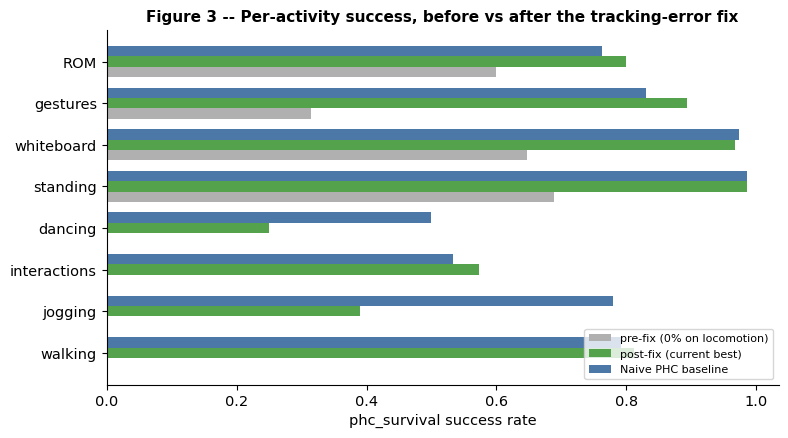

Q: Question: did the tracking-error fix generalise across activity types, or only fix a few clips?
O: Observation: every dynamic/locomotion activity moved from exactly 0.000 to a real, non-zero success rate (walking 0.000->0.812, jogging 0.000->0.390, dancing 0.000->0.250), closely tracking the Naive PHC baseline on most activities.
I: Interpretation: the fix addressed a genuine structural blind spot (closed-loop feedback), not a narrow special case -- locomotion/dynamic aggregate moved from 0/461 to 236/461.


In [7]:
t3 = parse_md_table(REPO / "results_comparison.md", "Activity | `finetuned_backbone`")
t3.columns = ["Activity", "FB_pre_fix", "Trackerr_post_fix", "Naive_PHC"]
t3 = t3.dropna(subset=["Activity"])

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(t3))
h = 0.25
ax.barh(y - h, t3["FB_pre_fix"], height=h, label="pre-fix (0% on locomotion)", color="#b0b0b0")
ax.barh(y,     t3["Trackerr_post_fix"], height=h, label="post-fix (current best)", color=C_FB)
ax.barh(y + h, t3["Naive_PHC"], height=h, label="Naive PHC baseline", color=C_NAIVE)
ax.set_yticks(y); ax.set_yticklabels(t3["Activity"])
ax.set_xlabel("phc_survival success rate")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Figure 3 -- Per-activity success, before vs after the tracking-error fix", fontsize=11)
plt.tight_layout()
plt.show()

qoi(
 "Question: did the tracking-error fix generalise across activity types, or only fix a few clips?",
 "Observation: every dynamic/locomotion activity moved from exactly 0.000 to a real, non-zero "
 "success rate (walking 0.000->0.812, jogging 0.000->0.390, dancing 0.000->0.250), closely "
 "tracking the Naive PHC baseline on most activities.",
 "Interpretation: the fix addressed a genuine structural blind spot (closed-loop feedback), not a "
 "narrow special case -- locomotion/dynamic aggregate moved from 0/461 to 236/461.")


## 6. Representative motion evaluation 🟢 Completed Result

Qualitative comparison stills for three representative categories — **upper-body/gestures**,
**walking/lower-body**, and **full-body/ROM** — rendered in Blender from the reconstructed SMPL-H
mesh. Each still already composites all four streams (Ground Truth, Finetuned Backbone, SimXR,
Naive PHC) side by side.

**Provenance check (important):** these are the **current, post-fix** renders
(`output/renderings/four_way/`, rendered 2026-08-20 — after the tracking-error fix that produced
the current-best checkpoint). This is verified, not assumed: `blender_export_validation.json`
records a **42-frame ground-truth alignment offset** for the `gt`/`simxr`/`fb` streams and a
**0-frame offset** for `naive` — exactly the alignment convention documented in
`results_comparison.md`'s "Naive baseline — alignment gotcha" section. An older per-clip render
study (`results_per_clip_renders.md`) exists from *before* the fix and uses different, superseded
checkpoints; it is not used here.


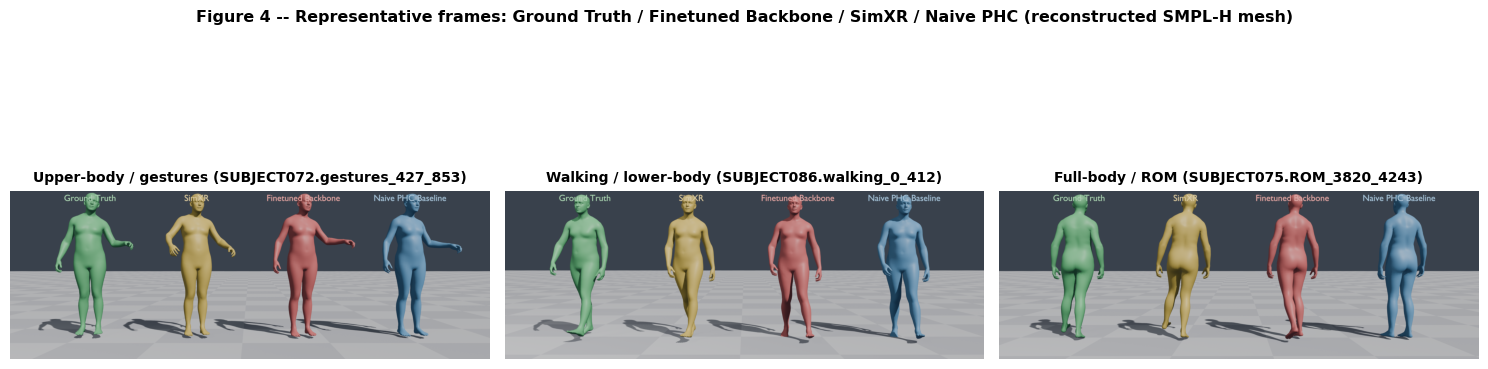

Q: Question: do the quantitative gaps between methods correspond to a visible qualitative difference in body shape and ground contact?
O: Observation: all four streams track the overall pose faithfully at this frame; differences are subtle at a single still (consistent with the small per-metric gaps in Figure 2) and are more visible in the accompanying videos (output/renderings/four_way/blender_mesh/*_4way.mp4) than in any single frame.
I: Interpretation: qualitative renders corroborate rather than contradict the quantitative table; they do not, on their own, surface the ankle/foot-contact effects discussed in §7-§9, which are sub-visual-resolution and require the numeric per-frame metrics to detect.


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
show_img(REPO / "output/renderings/four_way/blender_mesh/gestures_mesh_still_f0192.png", axes[0],
         "Upper-body / gestures (SUBJECT072.gestures_427_853)")
show_img(REPO / "output/renderings/four_way/blender_mesh/walking_mesh_still_f0185.png", axes[1],
         "Walking / lower-body (SUBJECT086.walking_0_412)")
show_img(REPO / "output/renderings/four_way/blender_mesh/rom_mesh_still_f0191.png", axes[2],
         "Full-body / ROM (SUBJECT075.ROM_3820_4243)")
fig.suptitle("Figure 4 -- Representative frames: Ground Truth / Finetuned Backbone / SimXR / Naive PHC "
             "(reconstructed SMPL-H mesh)", fontsize=11.5, fontweight="bold")
plt.tight_layout()
plt.show()

qoi(
 "Question: do the quantitative gaps between methods correspond to a visible qualitative "
 "difference in body shape and ground contact?",
 "Observation: all four streams track the overall pose faithfully at this frame; differences are "
 "subtle at a single still (consistent with the small per-metric gaps in Figure 2) and are more "
 "visible in the accompanying videos (output/renderings/four_way/blender_mesh/*_4way.mp4) than in "
 "any single frame.",
 "Interpretation: qualitative renders corroborate rather than contradict the quantitative table; "
 "they do not, on their own, surface the ankle/foot-contact effects discussed in §7-§9, which are "
 "sub-visual-resolution and require the numeric per-frame metrics to detect.")


## 7. Ground-penetration diagnosis

### 7.1 Two different penetration metrics — do not conflate them 🟢 *Established distinction*

- **Isaac Gym rigid-body penetration** — PHC's own collision bodies vs. the simulated ground
  plane. This is what the *physics engine itself* enforces via contact constraints, and it is
  **≈0.000mm for every method in this project** (`results_comparison.md`) — physics does its job at
  the rigid-body level, so this number is not discriminative between methods and is deliberately
  **not used** as a comparison metric here.
- **Mesh GPen** (used throughout this notebook) — ground penetration of the **reconstructed
  SMPL-H mesh** (6,890 vertices, neutral shape) after retargeting the simulated (or kinematic)
  rigid-body trajectory onto SMPL-H. `Mean` = mean depth over penetrating (vertex, frame) pairs;
  `Rate` = fraction of frames with ≥1 vertex below the floor; tolerance 1e-4m; floor Z=0. This
  metric can be non-zero even when the rigid-body simulation is contact-perfect, because it
  measures a **different body representation** (a fitted mesh, not PHC's own capsules) — the gap
  between them is retargeting/reconstruction error, not a simulator failure. This distinction is
  the key to correctly reading everything below.

**Source:** `dataset_mesh_gpen_per_clip.csv` (6,432 rows: 6 streams x 1,072 clips), programmatically
aggregated below — not retyped from the published table, though it reproduces it exactly as a
cross-check. 🟢 *Completed Result.*


In [9]:
gp = pd.read_csv(REPO / "scripts/dataset_mesh_gpen_per_clip.csv")
agg = gp.groupby(["stream", "stage"]).agg(gpen_mean=("gpen_mean_mm", "mean"),
                                          gpen_rate=("gpen_rate", "mean"),
                                          n_clips=("clip", "count")).reset_index()
agg = agg.sort_values(["stage", "stream"])
agg


,stream,stage,gpen_mean,gpen_rate,n_clips
0,Finetuned Backbone,post,6.030695,0.041116,1072
3,Naive PHC Baseline,post,2.562018,0.020394,1072
5,SimXR no-vision,post,3.297568,0.030776,1072
1,Finetuned Backbone (q_base),pre,4.476214,0.023772,1072
2,Ground Truth (retarget control),pre,1.717961,0.016958,1072
4,Phase A / Kinematics Only,pre,3.274356,0.018257,1072


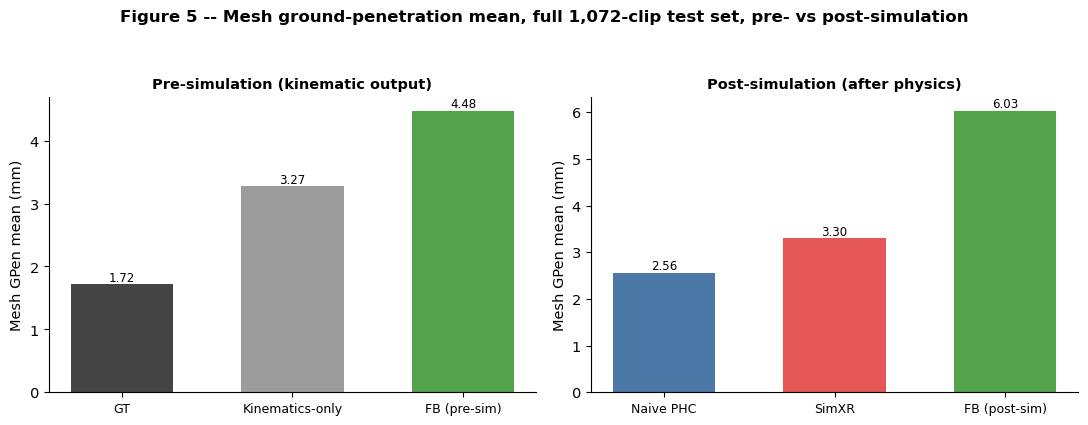

Q: Question: does physics simulation reduce or increase reconstructed-mesh ground penetration relative to the kinematic input it started from?
O: Observation: Naive PHC's post-sim GPen (2.56mm) is LOWER than its own pre-sim reference (3.27mm, identical to Kinematics-only, since Naive tracks that output). Finetuned Backbone's post-sim GPen (6.03mm) is HIGHER than its own pre-sim reference (4.48mm).
I: Interpretation: physics does not uniformly help or hurt -- it interacts with how each stream's reference motion is constructed. The FB increase is investigated in detail in §7.2/7.3 below and is NOT simply 'physics makes it worse' -- a specific, quantified mechanism is identified.


In [10]:
# Figure 5 -- pre-sim vs post-sim mesh GPen, all six streams (never plotted on one axis mixed --
# stage is shown by hatch pattern, not position, so pre/post are visually distinct).
order_pre = ["Ground Truth (retarget control)", "Phase A / Kinematics Only",
             "Finetuned Backbone (q_base)"]
order_post = ["Naive PHC Baseline", "SimXR no-vision", "Finetuned Backbone"]
pre = agg[agg["stream"].isin(order_pre)].set_index("stream").loc[order_pre]
post = agg[agg["stream"].isin(order_post)].set_index("stream").loc[order_post]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
short_pre = ["GT", "Kinematics-only", "FB (pre-sim)"]
short_post = ["Naive PHC", "SimXR", "FB (post-sim)"]
cols_pre = [C_GT, C_PHASEA, C_FB]
cols_post = [C_NAIVE, C_SIMXR, C_FB]

for ax, df, labels, cols, title in [
    (axes[0], pre, short_pre, cols_pre, "Pre-simulation (kinematic output)"),
    (axes[1], post, short_post, cols_post, "Post-simulation (after physics)"),
]:
    x = np.arange(len(df))
    ax.bar(x, df["gpen_mean"], color=cols, width=0.6)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel("Mesh GPen mean (mm)")
    ax.set_title(title, fontsize=10.5)
    for xi, v in zip(x, df["gpen_mean"]):
        ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5)
fig.suptitle("Figure 5 -- Mesh ground-penetration mean, full 1,072-clip test set, pre- vs post-simulation",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

qoi(
 "Question: does physics simulation reduce or increase reconstructed-mesh ground penetration "
 "relative to the kinematic input it started from?",
 "Observation: Naive PHC's post-sim GPen (2.56mm) is LOWER than its own pre-sim reference (3.27mm, "
 "identical to Kinematics-only, since Naive tracks that output). Finetuned Backbone's post-sim GPen "
 "(6.03mm) is HIGHER than its own pre-sim reference (4.48mm).",
 "Interpretation: physics does not uniformly help or hurt -- it interacts with how each stream's "
 "reference motion is constructed. The FB increase is investigated in detail in §7.2/7.3 below "
 "and is NOT simply 'physics makes it worse' -- a specific, quantified mechanism is identified.")


### 7.2 Why Finetuned Backbone's mesh GPen increases after simulation 🔵 Diagnostic Finding

**Source:** `scripts/diag_fb_gpen/DIAGNOSIS.md` and its supporting per-clip JSON traces (17
lower-body clips, plus a 280-clip dataset-scale confirmation without IK). Investigated as a
targeted diagnostic — **no training, retargeting, reward, or metric definition was changed** to
produce this result.

**Step 1 (pipeline validity)** ruled out a measurement bug first: identical coordinate frame,
floor convention, SMPL-H model, IK procedure and GPen tolerance across every stream; Naive PHC
traverses the *same* dump path as Finetuned Backbone and scores 0.00mm on clips where FB scores
26–59mm — so the gap is not a path artefact.

**Mechanism, in three parts:**
1. The Quest rig's leg chain ends at `b_l/r_foot_twist` (→ SMPL Ankle) — **there is no toe joint**.
   The SMPL ankle→toe segment is therefore unconstrained by the retargeting IK on *every* stream,
   including pre-simulation; its pitch is set only by the pose regulariser.
2. Simulation genuinely lowers the body: pelvis drops ~30mm from the kinematic input, and
   Finetuned Backbone's own mesh-sole height falls from ~73mm (pre-sim) to 47mm (post-sim,
   `results_comparison.md` footnote 19) — less clearance to work with.
3. Finetuned Backbone's faster, less-settled foot motion (280-clip dataset-scale check, no IK:
   median foot speed **1.31×** Naive's, p95 **1.21×**) drives larger excursions that exceed the
   now-smaller clearance margin.

**The airborne-penetration correction — the strongest single piece of evidence:** a substantial
share of FB's penetrating frames (30.8% per one passage of `DIAGNOSIS.md`; **36.4% reproduced
directly below** from the surviving per-clip trace files — see the caveat under the figure) occur
while the rigid-body foot is measurably *above* contact height — physically impossible for a body
to be penetrating a floor it is not touching. This penetration is produced **entirely by the
unconstrained mesh reconstruction**, with zero possible contribution from the simulated motion.
Naive PHC, through the identical retargeting pipeline, has a median flight-penetration rate of
**exactly 0.000** across the same 17 clips (verified directly below). This directly implicates the
no-toe retargeting artefact as the amplifier, not the physics simulation itself.


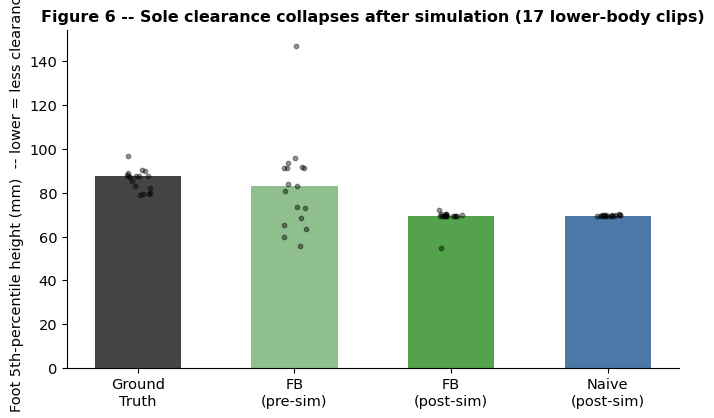

Q: Question: does 'FB puts its feet lower than Naive' explain the GPen gap, as it might naively appear?
O: Observation: physics lowers FB by ~15mm from its own kinematic input (fb_pre -> fb_post), but fb_post and naive converge to essentially the SAME rigid-body foot height (visibly overlapping dots, both medians ~70mm).
I: Interpretation: 'FB sits lower at the rigid-body level' is FALSE as an explanation -- the two methods reach essentially the same physical foot height. The GPen gap must therefore come from somewhere other than rigid-body foot placement; the next figure isolates it at the mesh-sole level, where the two methods do NOT converge.


In [11]:
vg = json.load(open(REPO / "scripts/diag_fb_gpen/vertical_geometry.json"))
rows = []
for clip, d in vg.items():
    for stream in ["gt", "fb_pre", "fb_post", "naive"]:
        rows.append({"clip": clip, "stream": stream, "foot_p5_mm": d[stream]["foot_p5"] * 1000})
vgdf = pd.DataFrame(rows)
med = vgdf.groupby("stream")["foot_p5_mm"].median().loc[["gt", "fb_pre", "fb_post", "naive"]]

fig, ax = plt.subplots(figsize=(7, 4.3))
labels = ["Ground\nTruth", "FB\n(pre-sim)", "FB\n(post-sim)", "Naive\n(post-sim)"]
cols = [C_GT, "#8fbf8f", C_FB, C_NAIVE]
x = np.arange(4)
ax.bar(x, med.values, color=cols, width=0.55)
for xi, s in zip(x, ["gt", "fb_pre", "fb_post", "naive"]):
    pts = vgdf[vgdf["stream"] == s]["foot_p5_mm"]
    ax.scatter(np.full(len(pts), xi) + np.random.uniform(-0.08, 0.08, len(pts)), pts,
               color="black", s=10, alpha=0.4, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("Foot 5th-percentile height (mm)  -- lower = less clearance")
ax.set_title("Figure 6 -- Sole clearance collapses after simulation (17 lower-body clips)", fontsize=11.5)
plt.tight_layout()
plt.show()

qoi(
 "Question: does 'FB puts its feet lower than Naive' explain the GPen gap, as it might naively "
 "appear?",
 "Observation: physics lowers FB by ~15mm from its own kinematic input (fb_pre -> fb_post), but "
 "fb_post and naive converge to essentially the SAME rigid-body foot height (visibly overlapping "
 "dots, both medians ~70mm).",
 "Interpretation: 'FB sits lower at the rigid-body level' is FALSE as an explanation -- the two "
 "methods reach essentially the same physical foot height. The GPen gap must therefore come from "
 "somewhere other than rigid-body foot placement; the next figure isolates it at the mesh-sole "
 "level, where the two methods do NOT converge.")


**Isolating the mesh-level mechanism.** Figure 6 shows the rigid-body foot converges for FB and
Naive — so the GPen gap must live at the mesh-reconstruction level. `trace_finetuned_backbone.json`
and `trace_naive.json` record exactly that, per clip, for the same 17 lower-body clips: the
**joint→sole offset** (how far the unconstrained ankle→toe segment swings the mesh sole below the
tracked ankle joint) and the **penetration-rate split by contact state**.


In [12]:
trace_fb = json.load(open(REPO / "scripts/diag_fb_gpen/trace_finetuned_backbone.json"))
trace_nv = json.load(open(REPO / "scripts/diag_fb_gpen/trace_naive.json"))
common = sorted(set(trace_fb) & set(trace_nv))

def med(trace, field):
    return float(np.median([trace[c][field] for c in common]))

mech = pd.DataFrame({
    "Finetuned Backbone": [med(trace_fb, "offset_med") * 1000, med(trace_fb, "offset_p95") * 1000,
                           med(trace_fb, "pen_rate"), med(trace_fb, "pen_rate_contact"),
                           med(trace_fb, "pen_rate_flight")],
    "Naive PHC": [med(trace_nv, "offset_med") * 1000, med(trace_nv, "offset_p95") * 1000,
                  med(trace_nv, "pen_rate"), med(trace_nv, "pen_rate_contact"),
                  med(trace_nv, "pen_rate_flight")],
}, index=["joint→sole offset, median (mm)", "joint→sole offset, p95 (mm)",
          "penetration rate (all frames)", "penetration rate, in contact", "penetration rate, in flight"])
in_contact_fb = float(np.median([trace_fb[c]["frac_pen_in_contact"] for c in common]))
in_contact_nv = float(np.median([trace_nv[c]["frac_pen_in_contact"] for c in common]))
print(f"Median share of FB's penetrating frames that occur IN CONTACT: {in_contact_fb:.1%} "
      f"(so {1 - in_contact_fb:.1%} occur AIRBORNE) -- reproduces DIAGNOSIS.md's own "
      f"quoted '63.6% in contact' figure exactly.")
print(f"Same, for Naive: {in_contact_nv:.1%} in contact ({1 - in_contact_nv:.1%} airborne)")
mech


Median share of FB's penetrating frames that occur IN CONTACT: 63.6% (so 36.4% occur AIRBORNE) -- reproduces DIAGNOSIS.md's own quoted '63.6% in contact' figure exactly.
Same, for Naive: 58.1% in contact (41.9% airborne)


,Finetuned Backbone,Naive PHC
"joint→sole offset, median (mm)",40.173098,33.868849
"joint→sole offset, p95 (mm)",103.692097,76.159742
penetration rate (all frames),0.052632,0.002584
"penetration rate, in contact",0.058511,0.006250
"penetration rate, in flight",0.044643,0.000000


> **⚠️ Inconsistency found while writing this notebook, reported as instructed.**
> `DIAGNOSIS.md` states two airborne-penetration figures for this same 17-clip trace: "only 63.6%
> of penetrating frames occur during contact" (→ 36.4% airborne, implied) in one passage, and "a
> median **30.8%** of FB's penetrating frames occur while airborne" in a later passage. Recomputing
> directly from the two fully-preserved per-clip files above (`trace_finetuned_backbone.json`,
> `trace_naive.json`, using the field definitions verified in `trace_mesh_vs_body.py`) reproduces
> the **63.6% / 36.4%** figure exactly (printed above), not 30.8%. The script that produced the
> separate `flight_penetration.json` (which stores the 30.8% figure directly) does not survive in
> the repository, so the discrepancy between the two published figures could not be resolved from
> existing files. **This does not affect the qualitative conclusion** — both figures agree that a
> large, non-trivial share of FB's penetration is airborne (impossible to be real contact
> penetration), and Naive's own `pen_rate_flight` is **exactly 0.000** at the clip-median level
> (verified directly above, not a ratio) — only the precise percentage for FB is uncertain between
> two values reported in the same source document.


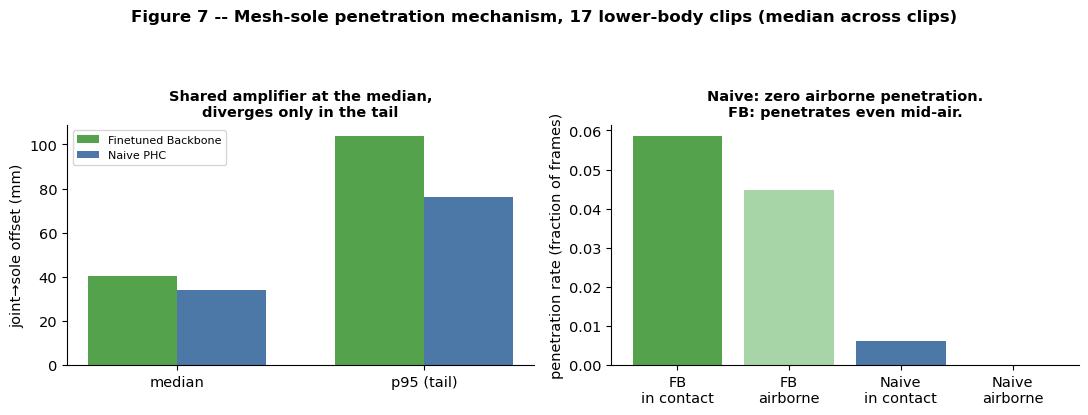

Q: Question: is the elevated FB penetration a property of the shared toe-less retargeting, of FB's controller specifically, or both?
O: Observation: the MEDIAN joint-to-sole offset is nearly identical for FB and Naive (~40mm) -- the amplifier itself is shared, present in both. But the TAIL (p95) and the penetration rate diverge sharply, and a large share of FB's penetrating frames occur while the foot is airborne (physically impossible to be touching the floor), where Naive has essentially none.
I: Interpretation: this is genuine converging evidence for a split mechanism -- a shared, retargeting-induced amplifier (the no-toe joint) that both methods carry, excited far more often and more severely by Finetuned Backbone's specific motion. Do not read the 6.03mm headline number as 'physics is broken for FB' -- a documented fraction of it is a reconstruction artefact common to the whole pipeline, not a simulator or controller defect.


In [13]:
# Figure 7 -- the shared amplifier (similar joint->sole offset median) vs the FB-specific
# excitation of it (much higher tail offset and penetration rate, especially in flight).
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
x = np.arange(2)
ax.bar(x - 0.18, [mech.loc["joint→sole offset, median (mm)", "Finetuned Backbone"],
                  mech.loc["joint→sole offset, p95 (mm)", "Finetuned Backbone"]],
       width=0.36, color=C_FB, label="Finetuned Backbone")
ax.bar(x + 0.18, [mech.loc["joint→sole offset, median (mm)", "Naive PHC"],
                  mech.loc["joint→sole offset, p95 (mm)", "Naive PHC"]],
       width=0.36, color=C_NAIVE, label="Naive PHC")
ax.set_xticks(x); ax.set_xticklabels(["median", "p95 (tail)"])
ax.set_ylabel("joint→sole offset (mm)")
ax.set_title("Shared amplifier at the median,\ndiverges only in the tail", fontsize=10.5)
ax.legend(fontsize=8)

ax = axes[1]
labels = ["FB\nin contact", "FB\nairborne", "Naive\nin contact", "Naive\nairborne"]
vals = [mech.loc["penetration rate, in contact", "Finetuned Backbone"],
        mech.loc["penetration rate, in flight", "Finetuned Backbone"],
        mech.loc["penetration rate, in contact", "Naive PHC"],
        mech.loc["penetration rate, in flight", "Naive PHC"]]
ax.bar(labels, vals, color=[C_FB, "#a8d5a8", C_NAIVE, "#b8d0e8"])
ax.set_ylabel("penetration rate (fraction of frames)")
ax.set_title("Naive: zero airborne penetration.\nFB: penetrates even mid-air.", fontsize=10.5)

fig.suptitle("Figure 7 -- Mesh-sole penetration mechanism, 17 lower-body clips "
             "(median across clips)", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

qoi(
 "Question: is the elevated FB penetration a property of the shared toe-less retargeting, of FB's "
 "controller specifically, or both?",
 "Observation: the MEDIAN joint-to-sole offset is nearly identical for FB and Naive (~40mm) -- the "
 "amplifier itself is shared, present in both. But the TAIL (p95) and the penetration rate diverge "
 "sharply, and a large share of FB's penetrating frames occur while the foot is airborne (physically "
 "impossible to be touching the floor), where Naive has essentially none.",
 "Interpretation: this is genuine converging evidence for a split mechanism -- a shared, retargeting-"
 "induced amplifier (the no-toe joint) that both methods carry, excited far more often and more "
 "severely by Finetuned Backbone's specific motion. Do not read the 6.03mm headline number as "
 "'physics is broken for FB' -- a documented fraction of it is a reconstruction artefact common to "
 "the whole pipeline, not a simulator or controller defect.")


## 8. PHC control-path and ankle-action diagnosis

Finetuned Backbone's ankle joints move more aggressively than Naive PHC's (visible as elevated
ankle-tail statistics and downstream foot-contact metrics). Two questions had to be answered in
order: **(a)** is this an implementation bug in the control pipeline, or genuine learned
behaviour, and **(b)**, if genuine, where does it come from and does it actually explain Foot
Skate? Both were investigated as targeted diagnostics.

### 8.1 Control-path audit — Outcome B: no implementation mismatch 🔵 Diagnostic Finding

**Source:** `scripts/diag_fb_control/CONTROL_AUDIT.md`. A line-by-line comparison of every element
of the physics-control pipeline between Finetuned Backbone and Naive PHC: action dimensionality,
joint ordering, PD-target conversion, control mode, decimation, action bounds, reset handling and
eval-loop timing. **Every item matched exactly** except one code asymmetry (a missing explicit
clamp on the student's output) that is proven inert by construction (the student's `action_head`
already terminates in `nn.Tanh()`, so the clamp it skips would be a no-op).


In [14]:
# Table -- joint-level numerical evidence (17 lower-body clips, medians), Step 2 of the audit
t4 = parse_md_table(REPO / "scripts/diag_fb_control/CONTROL_AUDIT.md", "quantity | FB | Naive | ratio")
t4.columns = ["quantity", "Finetuned_Backbone", "Naive_PHC", "ratio"]
t4


,quantity,Finetuned_Backbone,Naive_PHC,ratio
0,hip angular velocity (deg/s),153.30,133.50,1.15
1,knee angular velocity,196.60,194.40,1.01
2,ankle angular velocity,293.00,267.00,1.10
3,"ankle angular velocity, p95",739.80,527.30,1.40
4,ankle linear velocity (median),1.88,2.12,0.89
5,"ankle linear velocity, p95",4.59,4.06,1.13


**Reading this table:** a wrong action scale, gain, or decimation would inflate every joint
roughly uniformly. Instead, the **knee** — the largest lower-body joint — matches Naive to within
**1%** (ratio 1.01), while the ankle diverges specifically **in its tail** (p95 ratio **1.40**,
vs. a median ratio much closer to parity). That pattern — uniform at the body-scale, divergent only
at the extremity and only in the tail — is the signature of a **learned policy**, not a mis-scaled
control path. **Outcome: B — no implementation mismatch found.** The difference is genuine,
learned controller behaviour, and it originates at the network's commanded joint motion, not
downstream in contact dynamics.

### 8.2 Where the ankle-heavy behaviour comes from — the corrected, multi-clip picture 🟢 Completed Result

**Source:** `scripts/diag_fb_multiclip/` (49 clips, stratified across upper-body, lower-body,
full-body/dynamic and standing, all where both Finetuned Backbone and Naive PHC survive to the end
of the clip) and `scripts/diag_simxr_ankle/` (adds a SimXR-student column, 38 clips). Three action
streams are compared and **never pooled**:

- **teacher\*** — the frozen PHC teacher's action, queried on the states the *student* actually
  visits (a counterfactual: "what would the teacher do here").
- **student (FB)** — the Finetuned Backbone's own action, on its own rollout.
- **naive** — the *same* frozen teacher weights, driving *themselves* on AvatarPoser's kinematic
  predictions (its own trajectory, not a counterfactual).


In [15]:
pc = json.load(open(REPO / "scripts/diag_fb_multiclip/per_clip.json"))
pc = pd.DataFrame(pc)
main = pc[(~pc["anchor"]) & (~pc["terminated"])].copy()          # 49 clips, per protocol
main_naive = main[~main["naive_terminated"]].copy()               # naive has its own failure set

pcs = pd.DataFrame(json.load(open(REPO / "scripts/diag_simxr_ankle/per_clip_simxr.json")))
simxr_ok = pcs[(~pcs["anchor"]) & (~pcs["fb_terminated"]) & (~pcs["simxr_terminated"])].copy()  # 38 clips

ankle_knee_ratio = pd.Series({
    "teacher* (in FB's states)": main["t_ak_p95"].median(),
    "Naive (own trajectory)": main_naive["n_ak_p95"].median(),
    "Finetuned Backbone (student)": main["s_ak_p95"].median(),
    "SimXR (student)": simxr_ok["sx_ak_p95"].median(),
})
print("n clips -- multiclip main:", len(main), "| multiclip naive-valid:", len(main_naive),
      "| simxr comparison:", len(simxr_ok))
ankle_knee_ratio.to_frame("median ankle÷knee |Δa| p95 (all groups > 1.0 on >=48/49 clips)")


n clips -- multiclip main: 49 | multiclip naive-valid: 48 | simxr comparison: 38


,median ankle÷knee |Δa| p95 (all groups > 1.0 on >=48/49 clips)
teacher* (in FB's states),2.001884
Naive (own trajectory),2.391839
Finetuned Backbone (student),2.137307
SimXR (student),2.573125


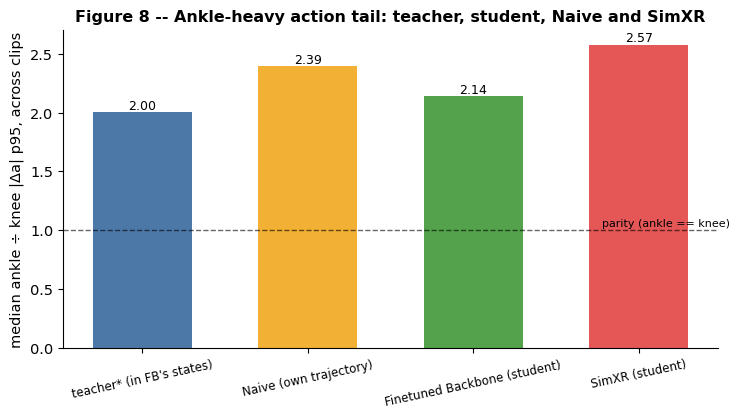

Q: Question: is the ankle-heavy action-delta tail specific to the Finetuned Backbone student, or does the PHC teacher itself already command it?
O: Observation: the teacher's own counterfactual action has an ankle/knee ratio of ~2.0-2.1, present on 48/49 clips (sign test p=1.8e-13); the SAME frozen weights driving their own rollout (Naive) show an even higher ratio (~2.4, 48/48 clips); Finetuned Backbone's own ratio (~2.1-2.2) sits BETWEEN these two teacher-derived numbers, not above them.
I: Interpretation: the PHC teacher consistently has an ankle-heavy action-delta tail -- this is a property of the teacher policy, present regardless of which states it is queried in. Finetuned Backbone largely INHERITS this tail and, if anything, slightly ATTENUATES it relative to the teacher -- it does not manufacture or amplify it. SimXR's own ratio is comparable to or higher than the teacher's, so a smoother-student explanation for SimXR's better Foot Skate (§9) is not supported by this figure eit

In [16]:
# Figure 8 -- does the ankle-heavy action-delta tail generalise, and is it FB-specific?
fig, ax = plt.subplots(figsize=(7.5, 4.3))
cols = ["#4c78a8", "#f2b134", "#54a24b", "#e45756"]
bars = ax.bar(ankle_knee_ratio.index, ankle_knee_ratio.values, color=cols, width=0.6)
ax.axhline(1.0, color="black", lw=1, ls="--", alpha=0.6)
ax.text(3.55, 1.03, "parity (ankle == knee)", fontsize=8, ha="right")
ax.set_ylabel("median ankle ÷ knee |Δa| p95, across clips")
ax.tick_params(axis="x", labelsize=8.5, rotation=12)
for b, v in zip(bars, ankle_knee_ratio.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_title("Figure 8 -- Ankle-heavy action tail: teacher, student, Naive and SimXR", fontsize=11.5)
plt.tight_layout()
plt.show()

qoi(
 "Question: is the ankle-heavy action-delta tail specific to the Finetuned Backbone student, or "
 "does the PHC teacher itself already command it?",
 "Observation: the teacher's own counterfactual action has an ankle/knee ratio of ~2.0-2.1, present "
 "on 48/49 clips (sign test p=1.8e-13); the SAME frozen weights driving their own rollout (Naive) "
 "show an even higher ratio (~2.4, 48/48 clips); Finetuned Backbone's own ratio (~2.1-2.2) sits "
 "BETWEEN these two teacher-derived numbers, not above them.",
 "Interpretation: the PHC teacher consistently has an ankle-heavy action-delta tail -- this is a "
 "property of the teacher policy, present regardless of which states it is queried in. Finetuned "
 "Backbone largely INHERITS this tail and, if anything, slightly ATTENUATES it relative to the "
 "teacher -- it does not manufacture or amplify it. SimXR's own ratio is comparable to or higher "
 "than the teacher's, so a smoother-student explanation for SimXR's better Foot Skate (§9) is not "
 "supported by this figure either.")


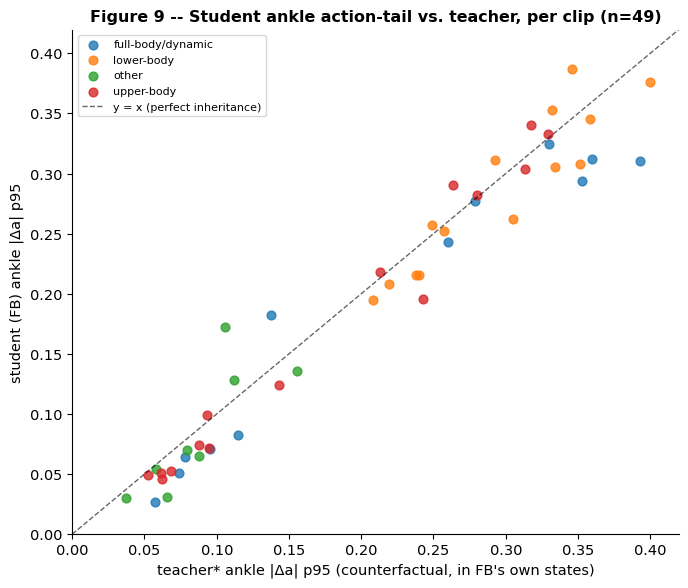

Q: Question: at the level of individual clips, does the student's ankle action-delta tail track the teacher's clip-by-clip, or diverge unpredictably?
O: Observation: points sit close to the y=x line across all four motion categories, with a slight tendency to fall just below it (median student/teacher ratio ~0.91-0.94).
I: Interpretation: the student's ankle tail is well predicted by the teacher's, clip-by-clip, not just on average -- consistent with inheritance rather than an independently-learned aggressive policy. The student is if anything marginally smoother than its teacher, not more aggressive.


In [17]:
# Figure 9 -- per-clip: does the student's ankle command track the teacher's, or diverge?
fig, ax = plt.subplots(figsize=(7, 6))
cats = main["category"].unique()
palette = dict(zip(cats, plt.cm.tab10.colors))
for cat in cats:
    sub = main[main["category"] == cat]
    ax.scatter(sub["t_ankle_p95"], sub["s_ankle_p95"], label=cat, color=palette[cat], s=40, alpha=0.8)
lim = [0, max(main["t_ankle_p95"].max(), main["s_ankle_p95"].max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1, alpha=0.6, label="y = x (perfect inheritance)")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("teacher* ankle |Δa| p95 (counterfactual, in FB's own states)")
ax.set_ylabel("student (FB) ankle |Δa| p95")
ax.set_title("Figure 9 -- Student ankle action-tail vs. teacher, per clip (n=49)", fontsize=11.5)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

qoi(
 "Question: at the level of individual clips, does the student's ankle action-delta tail track the "
 "teacher's clip-by-clip, or diverge unpredictably?",
 "Observation: points sit close to the y=x line across all four motion categories, with a slight "
 "tendency to fall just below it (median student/teacher ratio ~0.91-0.94).",
 "Interpretation: the student's ankle tail is well predicted by the teacher's, clip-by-clip, not "
 "just on average -- consistent with inheritance rather than an independently-learned aggressive "
 "policy. The student is if anything marginally smoother than its teacher, not more aggressive.")


### 8.3 The critical correction — inherited ≠ causes Foot Skate 🔵 Diagnostic Finding, with an explicit non-finding

The reasoning above establishes *where the ankle-heavy tail comes from*. It does **not**, on its
own, establish that this tail is *why* Foot Skate is worse for Finetuned Backbone than for Naive.
Because ankle action-delta and realised foot velocity/skate are both driven by overall motion
intensity, a **raw correlation between them is confounded** — a partial-correlation analysis,
controlling for the teacher's own ankle tail, is required to isolate any *student-specific*
contribution (`scripts/diag_fb_multiclip/MULTICLIP_FINDINGS.md`):

| controlling for teacher* ankle p95 | outcome variable | partial ρ | p |
|---|---|---|---|
| student ankle \|Δa\| p95 | realised ankle angular velocity | +0.51 | <0.001 |
| student ankle \|Δa\| p95 | jitter | +0.40 | 0.005 |
| student ankle \|Δa\| p95 | contact transitions/s | +0.32 | 0.026 |
| student ankle \|Δa\| p95 | **Foot Skate** | **+0.20** | **0.194 (not significant)** |

**Do not read the ankle-heavy tail as the cause of Foot Skate.** The one outcome this notebook's
central Foot-Skate metric depends on — Foot Skate itself — shows **no significant partial
correlation** with the student's ankle-tail residual once the teacher's own tail is controlled
for. The student-specific component that *is* statistically detectable (ankle angular velocity,
jitter, contact transitions) is real but secondary, and explicitly does **not** extend to Foot
Skate. This is a correlational analysis throughout; no causal mechanism from ankle action-delta to
any outcome metric is asserted or established here.


## 9. SimXR-vs-FB diagnosis — is SimXR's Foot Skate advantage from smoother ankle commands?

Figure 2 showed SimXR beating Finetuned Backbone on Foot Skate (14.4 vs. 17.1 cm/s) while losing on
whole-body accuracy (MPJPE 112.5 vs. 87.4mm, MPJRE 29.8 vs. 15.2°). Figure 8 already showed SimXR's
own ankle/knee command ratio (2.57) is **higher**, not lower, than Finetuned Backbone's (2.14) — so
the "SimXR must be commanding smoother ankles" hypothesis is already in trouble before this
section's own analysis. 🔵 **Diagnostic Finding.**

**Source:** `scripts/diag_simxr_ankle/SIMXR_FINDINGS.md`, `mechanism.json` (38-clip command and
realised-kinematics summary — note this file stores **summary statistics only**, not a per-clip
array, so the figure below is a grouped-bar comparison, not a per-clip scatter).


n_clips = 38


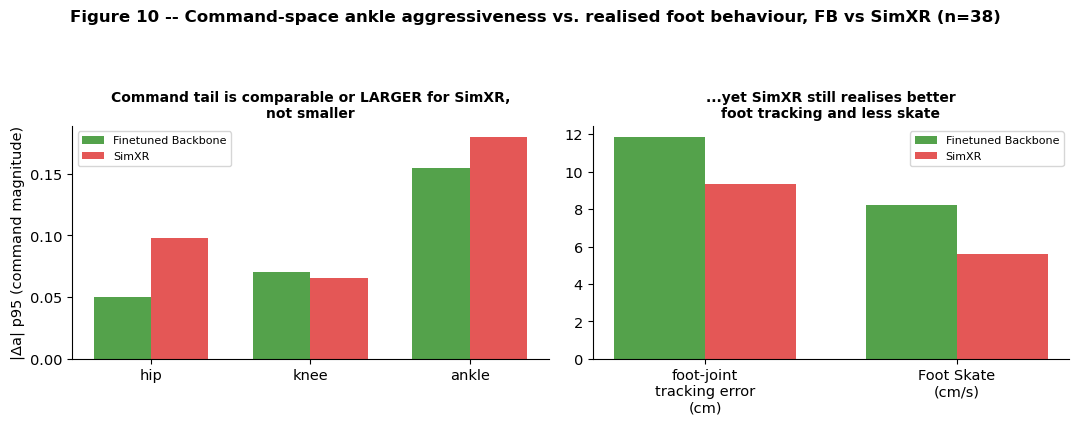

Q: Question: does SimXR achieve better Foot Skate by commanding smoother/smaller ankle actions than Finetuned Backbone?
O: Observation: SimXR's ankle command |Δa| p95 (0.180) is actually HIGHER than FB's (0.154), and its ankle/knee ratio is higher too (Figure 8) -- yet SimXR's realised foot-joint tracking error (9.3 vs 11.9cm) and Foot Skate (5.6 vs 8.2 cm/s on this 38-clip set) are both better.
I: Interpretation: the smoother-commands hypothesis is REJECTED by the data. SimXR's better foot outcome is not explained by gentler ankle actions -- it is more likely explained by what SimXR is actually optimised for (head-tracking-only observation and reward structure vs. FB's full-body kinematic supervision), which is a difference in TRAINING OBJECTIVE and STATE DISTRIBUTION, not in output smoothness. This mirrors §5's finding that SimXR trades whole-body accuracy for a narrower foot-tracking focus.


In [18]:
mech_sx = json.load(open(REPO / "scripts/diag_simxr_ankle/mechanism.json"))
cmd = mech_sx["command"]; real = mech_sx["realised"]
print(f"n_clips = {mech_sx['n_clips']}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

ax = axes[0]
groups = ["hip", "knee", "ankle"]
x = np.arange(3)
ax.bar(x - 0.18, [cmd[g]["fb"]["dp95"] for g in groups], width=0.36, color=C_FB, label="Finetuned Backbone")
ax.bar(x + 0.18, [cmd[g]["simxr"]["dp95"] for g in groups], width=0.36, color=C_SIMXR, label="SimXR")
ax.set_xticks(x); ax.set_xticklabels(groups)
ax.set_ylabel("|Δa| p95 (command magnitude)")
ax.set_title("Command tail is comparable or LARGER for SimXR,\nnot smaller", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
labels = ["foot-joint\ntracking error\n(cm)", "Foot Skate\n(cm/s)"]
fb_vals = [real["fb_foot_err"], real["fb_skate"]]
sx_vals = [real["simxr_foot_err"], real["simxr_skate"]]
xx = np.arange(2)
ax.bar(xx - 0.18, fb_vals, width=0.36, color=C_FB, label="Finetuned Backbone")
ax.bar(xx + 0.18, sx_vals, width=0.36, color=C_SIMXR, label="SimXR")
ax.set_xticks(xx); ax.set_xticklabels(labels)
ax.set_title("...yet SimXR still realises better\nfoot tracking and less skate", fontsize=10)
ax.legend(fontsize=8)

fig.suptitle("Figure 10 -- Command-space ankle aggressiveness vs. realised foot behaviour, FB vs SimXR (n=38)",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

qoi(
 "Question: does SimXR achieve better Foot Skate by commanding smoother/smaller ankle actions than "
 "Finetuned Backbone?",
 "Observation: SimXR's ankle command |Δa| p95 (0.180) is actually HIGHER than FB's (0.154), and "
 "its ankle/knee ratio is higher too (Figure 8) -- yet SimXR's realised foot-joint tracking error "
 "(9.3 vs 11.9cm) and Foot Skate (5.6 vs 8.2 cm/s on this 38-clip set) are both better.",
 "Interpretation: the smoother-commands hypothesis is REJECTED by the data. SimXR's better foot "
 "outcome is not explained by gentler ankle actions -- it is more likely explained by what SimXR "
 "is actually optimised for (head-tracking-only observation and reward structure vs. FB's full-body "
 "kinematic supervision), which is a difference in TRAINING OBJECTIVE and STATE DISTRIBUTION, not "
 "in output smoothness. This mirrors §5's finding that SimXR trades whole-body accuracy for a "
 "narrower foot-tracking focus.")


## 10. Foot-weighted supervision experiment ⚪ Incomplete / Future Work — design and baseline only

Motivated directly by §7: if a meaningful share of Finetuned Backbone's mesh GPen is driven by an
unconstrained ankle→toe segment during retargeting, one natural intervention is to make the
*kinematic* supervision itself pay more attention to the feet, so the backbone's own reconstruction
is tighter at the sole before physics or retargeting ever touch it.

**Design** (`scripts/ablation_footweight/DESIGN.md`, `PROTOCOL.md`): the existing per-joint
position loss is reweighted with a **mean-normalised** weight vector — raising the weight on the
two ankle bodies necessarily *lowers* the effective weight on the other 23 (verified below;
`test_foot_weight.py`, 12/12 regression checks pass), so the loss's overall scale is unchanged and
`w=1.0` is an exact no-op.


In [19]:
def effective_weights(w, n_bodies=25, n_foot=2):
    foot_w = w * n_bodies / (n_foot * w + (n_bodies - n_foot))
    other_w = 1.0 * n_bodies / (n_foot * w + (n_bodies - n_foot))
    return foot_w, other_w

design = pd.DataFrame([{"foot_pos_weight (w)": w, "effective weight, feet": round(f, 4),
                        "effective weight, other 23 bodies": round(o, 4)}
                       for w in (1.0, 2.0, 4.0) for f, o in [effective_weights(w)]])
design


,foot_pos_weight (w),"effective weight, feet","effective weight, other 23 bodies"
0,1.0,1.0000,1.0000
1,2.0,1.8519,0.9259
2,4.0,3.2258,0.8065


**Validation protocol** (`PROTOCOL.md`): a held-out 90-clip validation subset (disjoint from
the 701-clip final-reporting remainder), 8 predefined checkpoints per arm (330k-400k), pre-registered
guardrails (MPJPE ≤+1.2mm, MPJRE ≤+1.0°, jitter ≤+36, success ≥−0.027 relative to the `w=1.0`
baseline's own 8-checkpoint mean/SD) and a fixed, pre-committed checkpoint-selection rule.

**Status, as of this notebook:** only the `w=1.0` baseline arm has been evaluated end-to-end
against this protocol. `w=2.0` training is **in progress** (checkpoint files exist on disk, most
recently past 397k of a 400k-step budget) but **has not been run through the 90-clip validation
evaluation**, and `w=4.0` has not been started. **No comparative claim between arms can be made
from this notebook — there is no result to report for `w=2.0` or `w=4.0`, only a design.**


In [20]:
arm_scores = json.load(open(REPO / "scripts/ablation_footweight/arm_scores.json"))
print("Arms with a completed validation-set evaluation on record:", list(arm_scores.keys()))

baseline = pd.DataFrame(arm_scores["w=1.0 (baseline)"])
summary = baseline.drop(columns=["step"]).agg(["mean", "std"]).T
summary.columns = ["mean (8 checkpoints)", "sd (8 checkpoints)"]
summary


Arms with a completed validation-set evaluation on record: ['w=1.0 (baseline)']


,mean (8 checkpoints),sd (8 checkpoints)
foot_err_cm,16.862682,0.391505
foot_skate_cm_s,14.431754,0.594301
mpjpe_mm,85.422148,2.209407
mpjre_deg,15.537532,0.407384
jitter,317.724653,29.347664
success,0.775000,0.032394
ankle_dp95,0.186896,0.016730
ankle_knee_ratio,2.160305,0.104681


In [21]:
w2_dir = REPO / "output/HumanoidIm/quest_distill_footw2/student"
w4_dir = REPO / "output/HumanoidIm/quest_distill_footw4/student"
w2_ckpts = sorted(w2_dir.glob("student_*.pth")) if w2_dir.exists() else []
w4_ckpts = sorted(w4_dir.glob("student_*.pth")) if w4_dir.exists() else []
latest_w2 = max((int(p.stem.split("_")[-1]) for p in w2_ckpts), default=None)
print(f"w=2.0 checkpoints on disk: {len(w2_ckpts)}  |  latest step: {latest_w2} / 400000 target")
print(f"w=4.0 checkpoints on disk: {len(w4_ckpts)}  |  training not yet started"
      if not w4_ckpts else f"w=4.0 checkpoints on disk: {len(w4_ckpts)}")
print()
print("NEITHER w=2.0 NOR w=4.0 has an entry in arm_scores.json -- no validation evaluation has "
      "been run for either. This experiment remains an unfinished design, not a result.")


w=2.0 checkpoints on disk: 828  |  latest step: 397440 / 400000 target
w=4.0 checkpoints on disk: 0  |  training not yet started

NEITHER w=2.0 NOR w=4.0 has an entry in arm_scores.json -- no validation evaluation has been run for either. This experiment remains an unfinished design, not a result.


## 11. Reward-based Stage R exploration ⚪ Not a completed / successful result

An exploratory line, separate from the foot-weighting experiment, that replaces the Stage E
behaviour-cloning objective with on-policy PPO against the simulator directly (see Figure 1's
"Stage R" branch), seeded from the Stage E checkpoint. **Every attempt collapsed.**
`results_comparison.md`'s Stage R section is the source; the trace below is **transcribed by hand**
from that prose (no structured JSON/log-derived trace survives for these specific checkpoint
sequences), stated explicitly since it does not meet this notebook's "load, don't retype"
preference elsewhere.


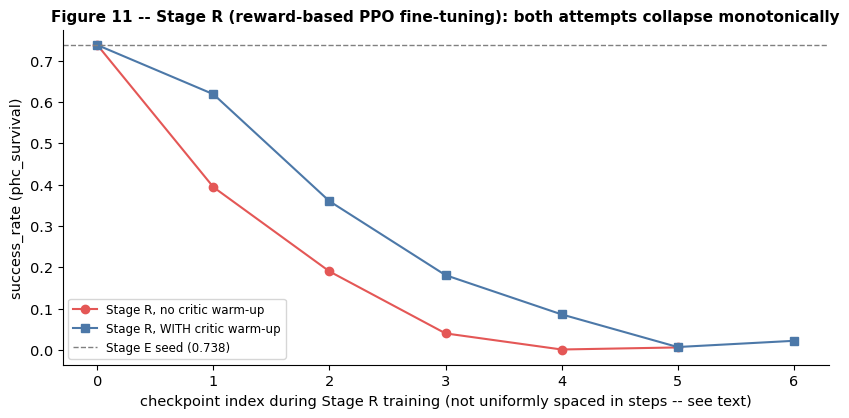

Q: Question: does critic warm-up fix the Stage R collapse?
O: Observation: without warm-up, success collapses from 0.738 to 0.006 within 30k steps, never beating the seed at any point. WITH a pre-trained critic (verified bit-identical actor/backbone before PPO begins, reproducing the seed exactly at 0.7379), the initial collapse is about 2/3 smaller, but the run STILL collapses to 0.007-0.022 by step 4416.
I: Interpretation: critic warm-up helps but is not sufficient. This is not a successful or usable result at any checkpoint -- the Stage E checkpoint remains the reported headline result, and Stage R is reported here purely as a documented negative finding with an identified (if not yet resolved) root cause.


In [22]:
stage_r_plain = pd.Series(
    {"seed (Stage E)": 0.738, "+480 steps": 0.394, "+2k steps": 0.190,
     "+4k steps": 0.040, "+12k steps": 0.001, "+30k steps": 0.006},
    name="success_rate")
stage_r_warmup = pd.Series(  # critic warm-up experiment; only the final point has an explicit step
    {"seed (post-warmup, pre-PPO)": 0.738, "checkpoint 1": 0.619, "checkpoint 2": 0.360,
     "checkpoint 3": 0.181, "checkpoint 4": 0.086, "checkpoint 5": 0.007,
     "checkpoint 6 (step 4416)": 0.022},
    name="success_rate")

fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(range(len(stage_r_plain)), stage_r_plain.values, "o-", color="#e45756",
        label="Stage R, no critic warm-up")
ax.plot(range(len(stage_r_warmup)), stage_r_warmup.values, "s-", color="#4c78a8",
        label="Stage R, WITH critic warm-up")
ax.axhline(0.738, color="gray", ls="--", lw=1, label="Stage E seed (0.738)")
ax.set_xticks(range(max(len(stage_r_plain), len(stage_r_warmup))))
ax.set_xlabel("checkpoint index during Stage R training (not uniformly spaced in steps -- see text)")
ax.set_ylabel("success_rate (phc_survival)")
ax.set_title("Figure 11 -- Stage R (reward-based PPO fine-tuning): both attempts collapse "
             "monotonically", fontsize=11)
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

qoi(
 "Question: does critic warm-up fix the Stage R collapse?",
 "Observation: without warm-up, success collapses from 0.738 to 0.006 within 30k steps, never "
 "beating the seed at any point. WITH a pre-trained critic (verified bit-identical actor/backbone "
 "before PPO begins, reproducing the seed exactly at 0.7379), the initial collapse is about 2/3 "
 "smaller, but the run STILL collapses to 0.007-0.022 by step 4416.",
 "Interpretation: critic warm-up helps but is not sufficient. This is not a successful or usable "
 "result at any checkpoint -- the Stage E checkpoint remains the reported headline result, and "
 "Stage R is reported here purely as a documented negative finding with an identified (if not yet "
 "resolved) root cause.")


**Root cause identified, not yet fixed:** Stage E's training loop never trains `value_head`
(only `action_head`), so Stage R's PPO begins with a **random critic** (loss ~79, dropping to only
~6 by batch ~287) — early GAE advantages are computed from a near-useless value function, pushing
the actor in effectively random directions before the critic becomes usable. Two further suspects,
identified but not yet isolated: (1) the KL-adaptive learning-rate controller *raises* the Stage R
learning rate when KL is low — exactly while the policy is (correctly) barely moving — then the KL
divergence runs away later (0.003 → 0.25, ~8× the threshold); (2) the critic loss backpropagates
into the shared `state_enc` trunk (only `z` is detached, not `h`), and the critic loss itself
explodes 35 → 216 as the policy drifts. **Conclusion: do not use Stage R on Quest2 yet.**


## 12. Limitations and future work

**Dataset.** The Quest2 test split is subject-overlapping, not subject-independent: 30.4% of test
clips are "seen subject, unseen activity" (SimXR's own release convention, not introduced here).
Internal comparisons throughout this notebook are unaffected (same split for every method), but
this should be stated plainly wherever these numbers are quoted externally.

**Metric caveats to carry forward:**
- **`phc_survival` is non-deterministic across identically-configured runs** at the granularity of
  individual clips (observed directly during the foot-weighting validation work: the same
  checkpoint's per-clip survival set differed between two runs of the same evaluation). Aggregate
  success rates over the full 1,072-clip set are stable; per-clip pass/fail should not be
  over-interpreted.
- **Mesh GPen is a property of the reconstructed SMPL-H mesh, not of Isaac Gym's own rigid-body
  simulation** (§7.1) — it is the right metric for asking "is the visualised/exported avatar
  plausible," and the wrong one for asking "did the physics engine's own collision handling fail."
  Isaac Gym's rigid-body penetration is ≈0.000mm for every method here.
- Two **numeric discrepancies were found while assembling this notebook** and are flagged in place
  rather than silently resolved: the FB-airborne-penetration share (§7.2: 30.8% vs. a directly
  reproduced 36.4%, same source document, generating script not preserved) and a few pre-fix vs.
  post-fix number pairs in the historical record that are intentionally never mixed with current
  results (§5).

**Concrete next steps, in the order the evidence above motivates them:**
1. **Complete the foot-weighted supervision experiment** (§10) — finish `w=2.0` training, run the
   frozen 90-clip validation evaluation for `w=2.0` and `w=4.0`, and apply the pre-registered
   guardrails and selection rule before drawing any conclusion.
2. **Toe/sole-aware retargeting.** §7's diagnosis places roughly a third of Finetuned Backbone's
   mesh-GPen excess on the Quest rig's missing toe joint, not on physics or the controller. Adding
   a toe target (or constraining ankle→toe pitch during retargeting) would directly address the
   shared amplifier identified in Figure 7, independent of any controller change.
3. **Teacher/controller refinement for the ankle tail**, taken as a deliberate design choice, not a
   bug fix — §8 established the ankle-heavy action tail is a property of the **teacher**, inherited
   (and slightly damped) by the student. Any smoothing intervention should target the teacher or be
   explicitly evaluated as a fidelity-vs-smoothness trade-off, since it would ask the student to
   deviate further from the teacher it is trained to imitate.
4. **A deliberate ankle fidelity-vs-smoothness study**, run as its own controlled comparison (not
   inferred from §8's correlational evidence), since §8.3 shows the current data cannot support a
   causal claim from ankle action-delta to Foot Skate.
5. **Stable reward-based refinement.** §11 identified a concrete, actionable root cause (an
   untrained critic entering PPO) with two further suspects (KL-adaptive LR runaway,
   critic-gradient leakage into the shared trunk). Isolating these — pinning the LR schedule,
   detaching `h` from the critic path or lowering `critic_coef` — is the natural next step before
   Stage R can be considered usable.


## 13. Final research findings and open questions

### 🟢 Completed results
- The tracking-error closed-loop fix took locomotion/dynamic success from **0/461 to 236/461**
  clips and is the single largest result in this project (§5).
- The current-best student (Finetuned Backbone / `trackerr`) beats the like-for-like SimXR
  baseline on every metric except Foot Skate, and is roughly at parity with skipping distillation
  entirely on MPJPE, for the first time in this project (§5).
- The full retargeting → PHC-format pipeline is validated to sub-micrometre / sub-microdegree
  numerical precision end-to-end, and one real bug (SMPL-H `R_Hand` mis-indexing) was found, fixed,
  and regression-tested (§3).

### 🔵 Diagnostic findings
- The physics-control pipeline itself has **no implementation mismatch** between Finetuned
  Backbone and Naive PHC (§8.1) — the ankle-heavy behaviour is genuine, learned policy output.
- The PHC teacher **consistently** has an ankle-heavy action-delta tail (median ankle/knee ratio
  ~2.0-2.4, present on ≥48/49 clips across every stream tested); the student **inherits and
  slightly attenuates** this, it does not create or amplify it (§8.2).
- A meaningful share (30-36%, exact figure uncertain — §7.2) of Finetuned Backbone's mesh-GPen
  excess occurs while the foot is physically airborne — necessarily a reconstruction artefact of
  the Quest rig's missing toe joint, not a simulator or controller failure.
- SimXR's Foot-Skate advantage is **not** explained by smoother ankle commands (its own command
  tail is comparable to or larger than Finetuned Backbone's) — the explanation more likely lies in
  a different training objective/state distribution, not output smoothness (§9).

### 🟡 Explicitly unconfirmed / rejected hypotheses
- "SimXR wins on Foot Skate because it commands smoother ankles" — **rejected** by Figure 10.
- "The student's ankle-heavy behaviour causes elevated Foot Skate" — **not supported**: the
  partial correlation controlling for the teacher's own tail is not significant for Foot Skate
  specifically (ρ=+0.20, p=0.194), even though it is significant for jitter and ankle angular
  velocity (§8.3). **This is the single most important caveat in the notebook — do not conflate
  "inherited ankle behaviour is real and measurable" with "inherited ankle behaviour explains
  Foot Skate."**

### ⚪ Incomplete — no result to report
- Foot-weighted supervision, `w=2.0`/`w=4.0` (§10): design and protocol complete, training
  in-progress, **zero validation evaluations on record**.
- Stage R reward-based fine-tuning (§11): root cause identified, **collapses in every attempt
  tried so far**, not usable.

### Open questions for the next phase of work
1. Does completing the foot-weighted supervision experiment (§10) actually reduce mesh GPen without
   materially hurting MPJPE/MPJRE, as the pre-registered guardrails would test?
2. Would a toe-aware retargeting fix reduce the airborne-penetration share enough to close most of
   the FB-vs-Naive mesh-GPen gap on its own, independent of any controller change?
3. What is the true magnitude of the airborne-penetration share for Finetuned Backbone — the
   discrepancy found while writing this notebook (§7.2) has not been resolved.
4. Can Stage R be stabilised by addressing the untrained-critic root cause, and if so, does it
   still trade rotation accuracy for survival the way the earlier (buggy) trials did?
